# Task 5 — Feedback Source: RLVR vs RLAIF (ATML PA2)
Runtime → Change runtime type → **GPU** (T4 is enough). Run cells top to bottom.

Three **frozen** policies, greedy decoding, identical prompts and generation settings:
**SFT** (base Qwen2.5-1.5B-Instruct, no adapter) · **RLVR** (course adapter `checkpoints/rlvr_policy`, exact final-answer verifier reward) · **RLAIF** (course adapter `checkpoints/rlaif_policy`, pairwise AI-judge group reward).
Nothing is retrained. The verifier (`task5_feedback/rlvr.py`) and the pairwise judge (`task5_feedback/rlaif.py`, Qwen2.5-3B-Instruct, deterministic A/B orientation balancing, cached) are the **unchanged** starter versions.

Pipeline: assets → data/schema checks → generate (GSM8K eval + fixed SVAMP-100) → exact verifier + format/length → fixed pairwise judge (RLVR vs SFT, RLAIF vs SFT, RLVR vs RLAIF) → controlled reward diagnostics (100 responses, 10 judged pairs per problem) → tables, plots, qualitative evidence, cost → discussion.

**Disconnect-safe:** `results/` is symlinked to `MyDrive/ATML_PA2_task5/results`; generation, judging and the judge cache are resumable — after a disconnect just re-run from the top.

| Step in the handout | Section |
|---|---|
| 1. In-domain comparison | §3 |
| 2. Reward-sensitivity / robustness (diagnostic set, S_reason, S_outcome) | §4 |
| 3. Out-of-domain comparison (SVAMP) | §5 |
| Qualitative diagnostic evidence | §6 |
| Feedback-source discussion (coverage, noise, exploitability, cost) + RQ1–4 | §7–8 |

In [1]:
%env PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
!nvidia-smi | head -15
import os
if not os.path.isdir('/content/ATML-PA2-LLM-PostTraining'):
    !git clone https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git
%cd /content/ATML-PA2-LLM-PostTraining

env: PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
Sat Oct 17 23:02:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  

In [2]:
# Persist results on Drive (resumable across disconnects)
from google.colab import drive
import os
drive.mount('/content/drive')
D = '/content/drive/MyDrive/ATML_PA2_task5'
os.makedirs(f'{D}/results', exist_ok=True)
if os.path.islink('results'): os.remove('results')
elif os.path.isdir('results'): os.system('rm -rf results')
os.symlink(f'{D}/results', 'results')
!ls -la results results/task5_feedback 2>/dev/null | head -30

Mounted at /content/drive
lrwxrwxrwx 1 root root 45 Oct 17 23:02 results -> /content/drive/MyDrive/ATML_PA2_task5/results


In [3]:
!pip install -q -r requirements.txt
!python -m scripts.download_assets
!python -m scripts.prepare_transfer_eval      # no-op if data/math_transfer_eval.jsonl already exists (never overwritten)
!python -m scripts.validate_assets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 111.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 109.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
Source: AbDu11aHHH/ATML-PA2-assets
Rev

## Frozen course adapters
Both adapters start from Qwen2.5-1.5B-Instruct and were prepared by the course on the same GSM8K prompts with the same group-based optimizer, group size, completion length and ≈matched token budget. This cell only **verifies** they are present.

In [4]:
import json, os, glob
from common.data import load_yaml
cfg = load_yaml('configs/feedback.yaml')
for name in ['rlvr', 'rlaif']:
    p = cfg['policies'][name]
    assert os.path.exists(f'{p}/adapter_config.json'), f'{name}: {p} missing — re-run scripts.download_assets'
    ac = json.load(open(f'{p}/adapter_config.json'))
    print(f"{name}: {p} OK | base={ac.get('base_model_name_or_path')} | r={ac.get('r')} | targets={ac.get('target_modules')}")
    for meta in glob.glob(f'{p}/*.json'):
        if os.path.basename(meta) not in ('adapter_config.json',):
            try: print('   ', os.path.basename(meta), '->', str(json.load(open(meta)))[:300])
            except Exception: pass

rlvr: checkpoints/rlvr_policy OK | base=Qwen/Qwen2.5-1.5B-Instruct | r=8 | targets=['v_proj', 'q_proj']
    added_tokens.json -> {'</tool_call>': 151658, '<tool_call>': 151657, '<|box_end|>': 151649, '<|box_start|>': 151648, '<|endoftext|>': 151643, '<|file_sep|>': 151664, '<|fim_middle|>': 151660, '<|fim_pad|>': 151662, '<|fim_prefix|>': 151659, '<|fim_suffix|>': 151661, '<|im_end|>': 151645, '<|im_start|>': 151644, '<|image
    tokenizer.json -> {'version': '1.0', 'truncation': None, 'padding': {'strategy': 'BatchLongest', 'direction': 'Left', 'pad_to_multiple_of': None, 'pad_id': 151643, 'pad_type_id': 0, 'pad_token': '<|endoftext|>'}, 'added_tokens': [{'id': 151643, 'content': '<|endoftext|>', 'single_word': False, 'lstrip': False, 'rstri
    vocab.json -> {'!': 0, '"': 1, '#': 2, '$': 3, '%': 4, '&': 5, "'": 6, '(': 7, ')': 8, '*': 9, '+': 10, ',': 11, '-': 12, '.': 13, '/': 14, '0': 15, '1': 16, '2': 17, '3': 18, '4': 19, '5': 20, '6': 21, '7': 22, '8': 23, '9': 24, ':': 25, ';':

## Student code
`rlvr.py` (exact verifier) and `rlaif.py` (pairwise judge) are used **unchanged**. The notebook implements
`metrics_t5.py` (format checks, failure types, pairwise bookkeeping, statistics), `evaluate_math.py` (generation + judging),
`score_perturbations.py` (controlled diagnostic scoring) and `compare_feedback.py` (all tables).

**Judge protocol (identical everywhere):** one call of the fixed `PairwiseAIJudge.compare(problem, A, B)` per pair. The judge itself decides the on-screen A/B orientation from a hash (orientation balancing), so position bias averages out across items; we additionally log which *physical* slot it picked to measure position bias at no extra cost. Byte-identical responses are scored `TIE` without a call. Win rate vs SFT = (wins + 0.5·ties)/n.
The three pairs per prompt (RLVR–SFT, RLAIF–SFT, RLVR–RLAIF) also give each response a K=3 direct-RLAIF group reward (wins + 0.5·ties)/(K−1), the same quantity RLAIF was trained on.

In [5]:
%%writefile task5_feedback/metrics_t5.py
"""Torch-free helpers for Task 5 (format checks, failure types, pairwise-preference bookkeeping, statistics)."""
from __future__ import annotations

import math
import re
import time

import numpy as np

from task5_feedback.rlvr import exact_reward, extract_designated_final, numerically_equal

_NUM_RE = re.compile(r"[-+]?\d[\d,]*(?:\.\d+)?")
_FINAL_SEG_RE = re.compile(r"####\s*[-+]?\d[\d,]*(?:\.\d+)?")
_FINAL_LINE_RE = re.compile(r"^\s*####\s*[-+]?\d[\d,]*(?:\.\d+)?\s*\.?\s*$")
FLIP = {"A": "B", "B": "A", "TIE": "TIE"}


# ----------------------------------------------------------------------------------------------------------- data access
def problem_text(row: dict) -> str:
    """Plain problem statement shown to the judge (no formatting instruction)."""
    for k in ("question", "problem", "prompt_text"):
        if row.get(k):
            return str(row[k])
    msgs = row.get("messages") or row.get("prompt")
    if isinstance(msgs, list):
        for m in reversed(msgs):
            if isinstance(m, dict) and m.get("role") == "user":
                return str(m.get("content", ""))
    if isinstance(msgs, str):
        return msgs
    raise KeyError(f"no problem text in row with keys {sorted(row)}")


def gold_final(row: dict) -> str:
    for k in ("gold_final", "gold", "final_answer", "answer_final", "gold_answer"):
        if row.get(k) not in (None, ""):
            return str(row[k]).replace(",", "").strip()
    if row.get("answer") not in (None, ""):
        ans = str(row["answer"])
        m = extract_designated_final(ans)
        return m if m is not None else ans.replace(",", "").strip()
    raise KeyError(f"no gold final answer in row with keys {sorted(row)}")


def response_text(row: dict) -> str:
    for k in ("response", "completion", "text", "candidate"):
        if k in row and row[k] is not None:
            return str(row[k])
    raise KeyError(f"no response text in row with keys {sorted(row)}")


# ----------------------------------------------------------------------------------------------------- response checks
def format_check(text: str) -> dict:
    """has_final: a designated `#### <number>` exists (what the verifier reads).
    strict_format: exactly one `####` marker and it is the last non-empty line."""
    t = str(text)
    pred = extract_designated_final(t)
    n_marks = t.count("####")
    lines = [ln for ln in t.strip().splitlines() if ln.strip()]
    last_ok = bool(lines) and bool(_FINAL_LINE_RE.match(lines[-1]))
    return {"has_final": pred is not None, "n_final_markers": n_marks,
            "strict_format": bool(pred is not None and n_marks == 1 and last_ok)}


def gold_in_text(text: str, gold) -> bool:
    return any(numerically_equal(x.replace(",", ""), gold) for x in _NUM_RE.findall(str(text)))


def failure_type(text: str, gold, truncated: bool = False) -> str:
    """correct | truncated_no_final | missing_final | gold_in_reasoning_wrong_final | wrong_final"""
    if exact_reward(text, gold) == 1.0:
        return "correct"
    if extract_designated_final(text) is None:
        return "truncated_no_final" if truncated else "missing_final"
    body = _FINAL_SEG_RE.sub(" ", str(text))
    return "gold_in_reasoning_wrong_final" if gold_in_text(body, gold) else "wrong_final"


# --------------------------------------------------------------------------------------------------- pairwise records
def verifier_pref(r_a: float, r_b: float) -> str:
    return "A" if r_a > r_b else ("B" if r_b > r_a else "TIE")


def pair_outcome(pref: str, better: str | None) -> str:
    """better / tie / wrong relative to the diagnostically better side ('A' or 'B'); 'n/a' if no ground truth."""
    if better is None:
        return "n/a"
    if pref == "TIE":
        return "tie"
    return "better" if pref == better else "wrong"


def judge_record(judge, problem: str, a: str, b: str) -> dict:
    """One call of the FIXED course judge (its own deterministic A/B orientation balancing + cache).
    Also records which physical slot the judge picked, to measure position bias without extra calls."""
    if str(a).strip() == str(b).strip():
        return {"judge_pref": "TIE", "identical": True, "cached": True, "secs": 0.0, "shown_first": None, "picked_slot": "TIE"}
    key = judge._key(problem, a, b)
    cached = key in judge.cache
    t0 = time.perf_counter()
    pref = judge.compare(problem, a, b)
    dt = time.perf_counter() - t0
    swap = int(key[:8], 16) % 2 == 1                      # same rule as PairwiseAIJudge.compare
    slot = "TIE" if pref == "TIE" else ("first" if (pref == "A") != swap else "second")
    return {"judge_pref": pref, "identical": False, "cached": cached, "secs": 0.0 if cached else dt,
            "shown_first": "b" if swap else "a", "picked_slot": slot}


def group_win_rates(k: int, prefs: dict) -> list[float]:
    """Direct-RLAIF group reward: (wins + 0.5 ties)/(K-1); prefs maps (i, j) with i<j to 'A'/'B'/'TIE'."""
    wins, ties = np.zeros(k), np.zeros(k)
    for (i, j), p in prefs.items():
        if p == "A":
            wins[i] += 1
        elif p == "B":
            wins[j] += 1
        else:
            ties[i] += 1
            ties[j] += 1
    return ((wins + 0.5 * ties) / max(k - 1, 1)).tolist()


# ---------------------------------------------------------------------------------------------------------- statistics
Z95 = 1.959964


def wilson(k: int, n: int, z: float = Z95):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def mcnemar_exact(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(0, min(b, c) + 1)) / 2 ** n)


def cohen_kappa(a, b, labels=("A", "B", "TIE")) -> float:
    a, b = np.asarray(a), np.asarray(b)
    if len(a) == 0:
        return float("nan")
    po = float((a == b).mean())
    pe = sum(float((a == l).mean()) * float((b == l).mean()) for l in labels)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def bootstrap_ci(values, n_boot: int = 2000, seed: int = 0, alpha: float = 0.05):
    v = np.asarray(values, dtype=float)
    if len(v) == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    means = v[rng.integers(0, len(v), size=(n_boot, len(v)))].mean(1)
    return (float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2)))


def point_biserial(x, y) -> float:
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if len(x) < 2 or x.std() == 0 or y.std() == 0:
        return float("nan")
    return float(np.corrcoef(x, y)[0, 1])

Writing task5_feedback/metrics_t5.py


In [6]:
%%writefile task5_feedback/evaluate_math.py
from __future__ import annotations

import argparse
import gc
import json
import time

import torch
from tqdm import tqdm

from common.data import load_yaml, prompt_messages, read_jsonl, repo_path, write_jsonl
from common.generation import batch_generate
from common.logging_utils import set_seed
from common.models import load_policy, load_tokenizer
from task5_feedback.metrics_t5 import (failure_type, format_check, gold_final, judge_record, problem_text,
                                       verifier_pref)
from task5_feedback.rlaif import PairwiseAIJudge
from task5_feedback.rlvr import exact_reward, extract_designated_final

POLICIES = ["sft", "rlvr", "rlaif"]
# (A, B) for every judged pair. A-vs-SFT gives the "RLAIF pairwise win rate against SFT"; rlvr-vs-rlaif is the
# head-to-head. All three pairs together give a K=3 direct-RLAIF group reward per prompt.
PAIRS = [("rlvr", "sft"), ("rlaif", "sft"), ("rlvr", "rlaif")]
DATASETS = ["gsm", "transfer"]


def policy_specs(cfg):
    return {
        "sft": None,
        "rlvr": cfg["policies"]["rlvr"],
        "rlaif": cfg["policies"]["rlaif"],
    }


def dataset_path(cfg, dataset: str):
    if dataset == "gsm":
        return cfg["paths"]["gsm_eval"]
    if dataset == "transfer":
        return cfg["paths"]["math_transfer_eval"]
    raise ValueError(dataset)


def load_math_evaluation(config_path: str, dataset: str):
    cfg = load_yaml(config_path)
    rows = read_jsonl(dataset_path(cfg, dataset))
    tokenizer = load_tokenizer(cfg["base_model"])
    return cfg, rows, tokenizer


def load_frozen_policy(cfg, name: str):
    specs = policy_specs(cfg)
    if name not in specs:
        raise KeyError(name)
    return load_policy(cfg, adapter_path=specs[name], trainable=False)


# ------------------------------------------------------------------------------------------------------------ paths
def out_dir(cfg):
    p = repo_path(cfg["results_dir"]) / "task5_feedback"
    p.mkdir(parents=True, exist_ok=True)
    return p


def gen_path(cfg, dataset, policy):
    return out_dir(cfg) / f"gen_{dataset}_{policy}.jsonl"


def judge_path(cfg, dataset):
    return out_dir(cfg) / f"judge_{dataset}.jsonl"


def judge_cache_path(cfg):
    return out_dir(cfg) / "judge_cache.json"


def load_judge(cfg):
    return PairwiseAIJudge(cfg, judge_cache_path(cfg))


# ------------------------------------------------------------------------------------------------------- generation
def generate_for_policy(cfg, rows, tokenizer, policy: str, batch_size: int = 16):
    """Greedy, identical decoding for every policy; fixed row order."""
    model = load_frozen_policy(cfg, policy)
    max_new = int(cfg["math_max_new_tokens"])
    recs, t0 = [], time.time()
    for s in tqdm(range(0, len(rows), batch_size), desc=f"gen {policy}"):
        chunk = rows[s:s + batch_size]
        gen = batch_generate(model, tokenizer, [prompt_messages(r) for r in chunk], max_prompt_length=512,
                             max_new_tokens=max_new, temperature=0.0, top_p=1.0, do_sample=False)
        for i, r in enumerate(chunk):
            resp, gold = gen["responses"][i], gold_final(r)
            trunc = bool(gen["truncated"][i])
            recs.append({
                "row_index": s + i,
                "source_index": str(r.get("source_index", r.get("prompt_id", s + i))),
                "policy": policy,
                "question": problem_text(r),
                "gold_final": gold,
                "response": resp,
                "response_tokens": int(gen["response_lengths"][i]),
                "response_words": len(resp.split()),
                "truncated": trunc,
                "terminated_with_eos": bool(gen["terminated_with_eos"][i]),
                "pred_final": extract_designated_final(resp),
                "exact": exact_reward(resp, gold),
                **format_check(resp),
                "failure_type": failure_type(resp, gold, trunc),
                **({"svamp_type": r["svamp_type"]} if "svamp_type" in r else {}),
            })
    secs = time.time() - t0
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return recs, secs


def run_generation(cfg, dataset, policies, batch_size):
    rows = read_jsonl(dataset_path(cfg, dataset))
    tokenizer = load_tokenizer(cfg["base_model"])
    timing_path = out_dir(cfg) / "generation_timing.json"
    timing = json.loads(timing_path.read_text()) if timing_path.exists() else {}
    for p in policies:
        adapter = policy_specs(cfg)[p]
        if adapter is not None and not repo_path(adapter).joinpath("adapter_config.json").exists():
            raise FileNotFoundError(f"{p}: no adapter at {adapter} (run scripts.download_assets)")
        path = gen_path(cfg, dataset, p)
        if path.exists() and len(read_jsonl(path)) == len(rows):
            print(f"[{dataset}/{p}] {path.name} already complete — skipping")
            continue
        recs, secs = generate_for_policy(cfg, rows, tokenizer, p, batch_size)
        write_jsonl(path, recs)
        timing[f"{dataset}/{p}"] = {"seconds": secs, "n": len(recs)}
        timing_path.write_text(json.dumps(timing, indent=1))
        acc = sum(r["exact"] for r in recs) / len(recs)
        print(f"[{dataset}/{p}] saved {len(recs)} responses -> {path.name} | exact acc {acc:.3f} | {secs:.0f}s")


# ------------------------------------------------------------------------------------------------------------ judging
def run_judging(cfg, judge, dataset):
    gens = {p: {r["source_index"]: r for r in read_jsonl(gen_path(cfg, dataset, p))} for p in POLICIES}
    ids = [r["source_index"] for r in read_jsonl(gen_path(cfg, dataset, "sft"))]
    for p in POLICIES:
        assert set(gens[p]) == set(ids), f"{dataset}: {p} was generated on a different prompt set"
    jp = judge_path(cfg, dataset)
    done = {(r["source_index"], r["a_policy"], r["b_policy"]) for r in read_jsonl(jp)} if jp.exists() else set()
    todo = [(sid, a, b) for sid in ids for a, b in PAIRS if (sid, a, b) not in done]
    print(f"[{dataset}] {len(ids)} prompts x {len(PAIRS)} pairs: {len(done)} judged, {len(todo)} to judge")
    with jp.open("a", encoding="utf-8") as f:
        for sid, a, b in tqdm(todo, desc=f"judge {dataset}"):
            ra, rb = gens[a][sid], gens[b][sid]
            rec = judge_record(judge, ra["question"], ra["response"], rb["response"])
            rec.update({"source_index": sid, "a_policy": a, "b_policy": b, "a_exact": ra["exact"], "b_exact": rb["exact"],
                        "verifier_pref": verifier_pref(ra["exact"], rb["exact"])})
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/feedback.yaml")
    ap.add_argument("--dataset", choices=["gsm", "transfer", "both"], default="gsm")
    ap.add_argument("--stage", choices=["generate", "judge", "all"], default="all")
    ap.add_argument("--policies", nargs="*", default=POLICIES)
    ap.add_argument("--batch-size", type=int, default=16)
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    set_seed(int(cfg["seed"]))
    datasets = DATASETS if args.dataset == "both" else [args.dataset]
    print("Datasets:", datasets, "| policies:", args.policies, "| greedy | max_new_tokens:", cfg["math_max_new_tokens"])
    if args.stage in ("generate", "all"):
        for d in datasets:
            run_generation(cfg, d, args.policies, args.batch_size)
    if args.stage in ("judge", "all"):
        judge = load_judge(cfg)
        print("Fixed pairwise judge loaded:", cfg["ai_judge_model"])
        for d in datasets:
            run_judging(cfg, judge, d)
    print("Done. Aggregate with: python -m task5_feedback.compare_feedback")


if __name__ == "__main__":
    main()

Overwriting task5_feedback/evaluate_math.py


In [7]:
%%writefile task5_feedback/score_perturbations.py
from __future__ import annotations

import argparse
import json
from collections import defaultdict

from tqdm import tqdm

from common.data import load_yaml, read_jsonl, repo_path, write_jsonl
from task5_feedback.metrics_t5 import (group_win_rates, judge_record, pair_outcome, problem_text, gold_final,
                                       response_text, verifier_pref)
from task5_feedback.rlvr import exact_reward, extract_designated_final

EXPECTED_VARIANTS = {
    "clean_correct",
    "corrupt_reasoning_correct_final",
    "good_reasoning_wrong_final",
    "persuasive_filler_correct",
    "gold_distractor_wrong_final",
}
# Fixed order: pairs below are (i, j) with i < j in this order, so the 10 judgments are exactly the ones
# PairwiseAIJudge.group_rewards would make for a K=5 group (shared cache) -> per-variant direct-RLAIF reward.
VARIANT_ORDER = ["clean_correct", "corrupt_reasoning_correct_final", "good_reasoning_wrong_final",
                 "persuasive_filler_correct", "gold_distractor_wrong_final"]
SHORT = {"clean_correct": "clean", "corrupt_reasoning_correct_final": "reason_corrupt",
         "good_reasoning_wrong_final": "wrong_final", "persuasive_filler_correct": "filler",
         "gold_distractor_wrong_final": "gold_distractor"}
# (first, second, diagnostically better side or None, pair name, family)
CONTROLLED_PAIRS = [
    ("clean_correct", "corrupt_reasoning_correct_final", "A", "clean>reason_corrupt", "reasoning sensitivity"),
    ("clean_correct", "good_reasoning_wrong_final", "A", "clean>wrong_final", "outcome sensitivity"),
    ("clean_correct", "persuasive_filler_correct", "A", "clean>filler", "style / verbosity"),
    ("clean_correct", "gold_distractor_wrong_final", "A", "clean>gold_distractor", "outcome sensitivity (distractor)"),
    ("corrupt_reasoning_correct_final", "good_reasoning_wrong_final", None, "reason_corrupt vs wrong_final", "process vs outcome"),
    ("corrupt_reasoning_correct_final", "persuasive_filler_correct", "B", "filler>reason_corrupt", "cross"),
    ("corrupt_reasoning_correct_final", "gold_distractor_wrong_final", None, "reason_corrupt vs gold_distractor", "process vs outcome"),
    ("good_reasoning_wrong_final", "persuasive_filler_correct", "B", "filler>wrong_final", "style vs outcome"),
    ("good_reasoning_wrong_final", "gold_distractor_wrong_final", None, "wrong_final vs gold_distractor", "distractor (no gold)"),
    ("persuasive_filler_correct", "gold_distractor_wrong_final", "A", "filler>gold_distractor", "style vs outcome"),
]


def load_diagnostic_groups(path):
    rows = read_jsonl(path)
    by_problem = defaultdict(dict)
    for row in rows:
        by_problem[str(row["problem_id"])][row["variant_type"]] = row
    for pid, variants in by_problem.items():
        missing = EXPECTED_VARIANTS - set(variants)
        if missing:
            raise ValueError(f"Problem {pid} missing variants: {sorted(missing)}")
    return by_problem


def _problem_and_gold(variants: dict):
    """Problem text / gold are shared by the 5 variants; take them from any variant that carries them."""
    prob = gold = None
    for v in VARIANT_ORDER:
        r = variants[v]
        if prob is None:
            try:
                prob = problem_text(r)
            except KeyError:
                pass
        if gold is None:
            try:
                gold = gold_final(r)
            except KeyError:
                pass
    if prob is None or gold is None:
        raise KeyError(f"diagnostic rows need a problem text and gold answer; keys: {sorted(variants[VARIANT_ORDER[0]])}")
    return prob, gold


def score_diagnostics(groups, judge):
    """Returns (pair_records, variant_records)."""
    pairs, variants_out = [], []
    idx = {v: i for i, v in enumerate(VARIANT_ORDER)}
    for pid in tqdm(sorted(groups, key=lambda x: (len(x), x)), desc="diagnostic problems"):
        g = groups[pid]
        problem, gold = _problem_and_gold(g)
        resp = {v: response_text(g[v]) for v in VARIANT_ORDER}
        rew = {v: exact_reward(resp[v], gold) for v in VARIANT_ORDER}
        prefs = {}
        for first, second, better, name, family in CONTROLLED_PAIRS:
            j = judge_record(judge, problem, resp[first], resp[second])
            vp = verifier_pref(rew[first], rew[second])
            prefs[(idx[first], idx[second])] = j["judge_pref"]
            pairs.append({"problem_id": pid, "pair": name, "family": family, "first": SHORT[first], "second": SHORT[second],
                          "better": better, "verifier_first": rew[first], "verifier_second": rew[second],
                          "verifier_pref": vp, "verifier_outcome": pair_outcome(vp, better),
                          "judge_outcome": pair_outcome(j["judge_pref"], better), **j})
        gw = group_win_rates(len(VARIANT_ORDER), prefs)
        for v in VARIANT_ORDER:
            variants_out.append({"problem_id": pid, "variant": SHORT[v], "variant_type": v, "gold_final": gold,
                                 "pred_final": extract_designated_final(resp[v]), "verifier_reward": rew[v],
                                 "rlaif_group_reward": gw[idx[v]], "response_words": len(resp[v].split()),
                                 "response": resp[v], "problem": problem})
    return pairs, variants_out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/feedback.yaml")
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    groups = load_diagnostic_groups(cfg["paths"]["task5_diagnostics"])
    print("Diagnostic problems:", len(groups), "| variants/problem:", len(VARIANT_ORDER), "| judged pairs/problem:", len(CONTROLLED_PAIRS))
    from task5_feedback.evaluate_math import load_judge, out_dir   # lazy: keeps this module importable without a GPU
    judge = load_judge(cfg)
    pairs, variants = score_diagnostics(groups, judge)
    od = out_dir(cfg)
    write_jsonl(od / "diag_pairs.jsonl", pairs)
    write_jsonl(od / "diag_variants.jsonl", variants)
    vr = defaultdict(list)
    for r in variants:
        vr[r["variant"]].append(r["verifier_reward"])
    print("Verifier reward by variant:", {k: sum(v) / len(v) for k, v in vr.items()})
    print("Saved", od / "diag_pairs.jsonl", "and", od / "diag_variants.jsonl")


if __name__ == "__main__":
    main()

Overwriting task5_feedback/score_perturbations.py


In [8]:
%%writefile task5_feedback/compare_feedback.py
"""Aggregate Task 5: in-domain (GSM8K), controlled reward diagnostics, out-of-domain (SVAMP), cost.  Torch-free."""
from __future__ import annotations

import argparse
import json
import timeit

import numpy as np
import pandas as pd

from common.data import load_yaml, read_jsonl, repo_path
from task5_feedback.metrics_t5 import (bootstrap_ci, cohen_kappa, group_win_rates, mcnemar_exact, point_biserial,
                                       wilson)
from task5_feedback.rlvr import exact_reward

POLICIES = ["sft", "rlvr", "rlaif"]
PAIRS = [("rlvr", "sft"), ("rlaif", "sft"), ("rlvr", "rlaif")]
FAIL_TYPES = ["correct", "wrong_final", "gold_in_reasoning_wrong_final", "missing_final", "truncated_no_final"]


def out_dir(cfg):
    p = repo_path(cfg["results_dir"]) / "task5_feedback"
    p.mkdir(parents=True, exist_ok=True)
    return p


def load_gens(cfg, dataset) -> pd.DataFrame:
    frames = []
    for p in POLICIES:
        path = out_dir(cfg) / f"gen_{dataset}_{p}.jsonl"
        if not path.exists():
            raise FileNotFoundError(f"{path} missing — run task5_feedback.evaluate_math --dataset {dataset}")
        frames.append(pd.DataFrame(read_jsonl(path)))
    return pd.concat(frames, ignore_index=True)


def load_judgments(cfg, dataset) -> pd.DataFrame:
    path = out_dir(cfg) / f"judge_{dataset}.jsonl"
    if not path.exists():
        raise FileNotFoundError(f"{path} missing — run task5_feedback.evaluate_math --dataset {dataset} --stage judge")
    return pd.DataFrame(read_jsonl(path))


# ------------------------------------------------------------------------------------------------- policy-level table
def policy_table(gens: pd.DataFrame, judg: pd.DataFrame, seed: int = 0) -> pd.DataFrame:
    rows = []
    for p in POLICIES:
        d = gens[gens.policy == p]
        n, k = len(d), int(d.exact.sum())
        lo, hi = wilson(k, n)
        row = {"policy": p, "n": n, "exact_acc": k / n, "exact_acc_lo": lo, "exact_acc_hi": hi,
               "has_final_rate": d.has_final.mean(), "strict_format_rate": d.strict_format.mean(),
               "truncated_rate": d.truncated.mean(), "mean_tokens": d.response_tokens.mean(),
               "median_tokens": d.response_tokens.median(), "mean_words": d.response_words.mean()}
        if p == "sft":
            row.update({"win_vs_sft": 0.5, "win_vs_sft_lo": np.nan, "win_vs_sft_hi": np.nan,
                        "W": np.nan, "T": np.nan, "L": np.nan})
        else:
            j = judg[(judg.a_policy == p) & (judg.b_policy == "sft")]
            s = j.judge_pref.map({"A": 1.0, "TIE": 0.5, "B": 0.0}).values
            lo, hi = bootstrap_ci(s, seed=seed)
            row.update({"win_vs_sft": float(s.mean()) if len(s) else np.nan, "win_vs_sft_lo": lo, "win_vs_sft_hi": hi,
                        "W": int((j.judge_pref == "A").sum()), "T": int((j.judge_pref == "TIE").sum()),
                        "L": int((j.judge_pref == "B").sum())})
        rows.append(row)
    return pd.DataFrame(rows).set_index("policy")


def head_to_head(judg: pd.DataFrame, seed: int = 0) -> dict:
    j = judg[(judg.a_policy == "rlvr") & (judg.b_policy == "rlaif")]
    s = j.judge_pref.map({"A": 1.0, "TIE": 0.5, "B": 0.0}).values
    lo, hi = bootstrap_ci(s, seed=seed)
    return {"rlvr_win_rate_vs_rlaif": float(s.mean()) if len(s) else float("nan"), "lo": lo, "hi": hi,
            "rlvr_wins": int((j.judge_pref == "A").sum()), "ties": int((j.judge_pref == "TIE").sum()),
            "rlaif_wins": int((j.judge_pref == "B").sum()), "n": len(j)}


def paired_accuracy_tests(gens: pd.DataFrame) -> pd.DataFrame:
    wide = gens.pivot(index="source_index", columns="policy", values="exact").astype(bool)
    rows = []
    for a, b in PAIRS:
        only_a, only_b = int((wide[a] & ~wide[b]).sum()), int((~wide[a] & wide[b]).sum())
        rows.append({"A": a, "B": b, "acc_A": wide[a].mean(), "acc_B": wide[b].mean(), "only_A_correct": only_a,
                     "only_B_correct": only_b, "mcnemar_p": mcnemar_exact(only_a, only_b)})
    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------------ verifier vs judge agreement
def agreement_table(judg: pd.DataFrame) -> pd.DataFrame:
    """Per comparison: 3-way agreement / kappa between verifier preference (exact_A vs exact_B) and judge preference.
    'decisive' = exactly one response correct (verifier has an opinion); 'verifier_tie' = both right or both wrong."""
    rows = []
    groups = [(f"{a} vs {b}", judg[(judg.a_policy == a) & (judg.b_policy == b)]) for a, b in PAIRS] + [("pooled", judg)]
    for name, j in groups:
        dec, tie = j[j.verifier_pref != "TIE"], j[j.verifier_pref == "TIE"]
        both_right = tie[tie.a_exact == 1]
        both_wrong = tie[tie.a_exact == 0]
        rows.append({
            "comparison": name, "n": len(j),
            "agreement_3way": float((j.verifier_pref == j.judge_pref).mean()) if len(j) else np.nan,
            "cohen_kappa": cohen_kappa(j.verifier_pref, j.judge_pref),
            "n_decisive": len(dec),
            "judge_picks_correct": float((dec.judge_pref == dec.verifier_pref).mean()) if len(dec) else np.nan,
            "judge_tie_when_decisive": float((dec.judge_pref == "TIE").mean()) if len(dec) else np.nan,
            "judge_picks_incorrect": float(((dec.judge_pref != "TIE") & (dec.judge_pref != dec.verifier_pref)).mean()) if len(dec) else np.nan,
            "n_verifier_tie": len(tie),
            "judge_decisive_when_verifier_tie": float((tie.judge_pref != "TIE").mean()) if len(tie) else np.nan,
            "n_both_correct": len(both_right),
            "judge_decisive_both_correct": float((both_right.judge_pref != "TIE").mean()) if len(both_right) else np.nan,
            "n_both_wrong": len(both_wrong),
            "judge_decisive_both_wrong": float((both_wrong.judge_pref != "TIE").mean()) if len(both_wrong) else np.nan,
        })
    return pd.DataFrame(rows).set_index("comparison")


def group_reward_table(gens: pd.DataFrame, judg: pd.DataFrame):
    """Per prompt, the three pairwise judgments define a K=3 direct-RLAIF group reward for each policy's response.
    Compare it with the binary verifier reward on the same responses."""
    idx = {p: i for i, p in enumerate(POLICIES)}
    recs = []
    for sid, j in judg.groupby("source_index"):
        if len(j) < len(PAIRS):
            continue
        prefs = {}
        for _, r in j.iterrows():
            i, k = idx[r.a_policy], idx[r.b_policy]
            p = r.judge_pref
            if i > k:
                i, k, p = k, i, {"A": "B", "B": "A", "TIE": "TIE"}[p]
            prefs[(i, k)] = p
        gw = group_win_rates(3, prefs)
        for p in POLICIES:
            recs.append({"source_index": sid, "policy": p, "rlaif_group_reward": gw[idx[p]]})
    g = pd.DataFrame(recs).merge(gens[["source_index", "policy", "exact", "response_words"]], on=["source_index", "policy"])
    summary = {"n_responses": len(g),
               "corr_group_reward_vs_exact": point_biserial(g.rlaif_group_reward, g.exact),
               "corr_group_reward_vs_words": point_biserial(g.rlaif_group_reward, g.response_words),
               "mean_group_reward_correct": float(g.loc[g.exact == 1, "rlaif_group_reward"].mean()),
               "mean_group_reward_incorrect": float(g.loc[g.exact == 0, "rlaif_group_reward"].mean()),
               "mean_group_reward_by_policy": g.groupby("policy").rlaif_group_reward.mean().round(4).to_dict()}
    return g, summary


def failure_table(gens: pd.DataFrame) -> pd.DataFrame:
    return (pd.crosstab(gens.policy, gens.failure_type, normalize="index")
            .reindex(index=POLICIES, columns=FAIL_TYPES, fill_value=0.0))


def judge_position_bias(judg: pd.DataFrame) -> dict:
    j = judg[~judg.identical.astype(bool)]
    nt = j[j.picked_slot != "TIE"]
    return {"n_nonidentical": len(j), "tie_rate": float((j.judge_pref == "TIE").mean()) if len(j) else np.nan,
            "picked_first_shown_rate_non_tie": float((nt.picked_slot == "first").mean()) if len(nt) else np.nan,
            "identical_pairs": int(judg.identical.astype(bool).sum())}


# ------------------------------------------------------------------------------------------- controlled diagnostics
def diagnostic_tables(cfg):
    od = out_dir(cfg)
    if not (od / "diag_pairs.jsonl").exists():
        raise FileNotFoundError("diag_pairs.jsonl missing — run task5_feedback.score_perturbations")
    pairs = pd.DataFrame(read_jsonl(od / "diag_pairs.jsonl"))
    var = pd.DataFrame(read_jsonl(od / "diag_variants.jsonl"))
    rows = []
    for (name, fam), d in pairs.groupby(["pair", "family"], sort=False):
        row = {"pair": name, "family": fam, "n": len(d), "has_ground_truth": d.better.notna().all()}
        for mech, col, pcol in [("verifier", "verifier_outcome", "verifier_pref"), ("judge", "judge_outcome", "judge_pref")]:
            if row["has_ground_truth"]:
                for o in ("better", "tie", "wrong"):
                    row[f"{mech}_{o}"] = float((d[col] == o).mean())
            else:   # no diagnostic ground truth: report which side the mechanism favours
                row[f"{mech}_prefers_first"] = float((d[pcol] == "A").mean())
                row[f"{mech}_tie"] = float((d[pcol] == "TIE").mean())
                row[f"{mech}_prefers_second"] = float((d[pcol] == "B").mean())
        rows.append(row)
    pair_tab = pd.DataFrame(rows).set_index("pair")

    order = ["clean", "reason_corrupt", "wrong_final", "filler", "gold_distractor"]
    var_tab = (var.groupby("variant").agg(n=("verifier_reward", "size"), verifier_reward=("verifier_reward", "mean"),
                                          rlaif_group_reward=("rlaif_group_reward", "mean"),
                                          rlaif_group_reward_sd=("rlaif_group_reward", "std"),
                                          mean_words=("response_words", "mean")).reindex(order))
    # rank of each variant within its problem under the RLAIF group reward (1 = best)
    var["rlaif_rank"] = var.groupby("problem_id").rlaif_group_reward.rank(ascending=False, method="average")
    var_tab["mean_rlaif_rank"] = var.groupby("variant").rlaif_rank.mean().reindex(order)
    # how often each variant gets the (possibly shared) highest RLAIF group reward in its problem
    mx = var.groupby("problem_id").rlaif_group_reward.transform("max")
    n_at_max = var.assign(m=var.rlaif_group_reward == mx).groupby("problem_id").m.transform("sum")
    var_tab["top_or_tied_rate"] = var.assign(t=var.rlaif_group_reward == mx).groupby("variant").t.mean().reindex(order)
    var_tab["strict_top_rate"] = var.assign(t=(var.rlaif_group_reward == mx) & (n_at_max == 1)).groupby("variant").t.mean().reindex(order)

    def S(pair, mech):
        d = pairs[pairs.pair == pair]
        col = f"{mech}_outcome"
        return {"S": float((d[col] == "better").mean()), "tie": float((d[col] == "tie").mean()),
                "wrong": float((d[col] == "wrong").mean()), "n": len(d)}

    sens = {}
    for mech in ("verifier", "judge"):
        sens[mech] = {
            "S_reason (clean > reason_corrupt)": S("clean>reason_corrupt", mech),
            "S_outcome (clean > wrong_final)": S("clean>wrong_final", mech),
            "S_outcome_distractor (clean > gold_distractor)": S("clean>gold_distractor", mech),
            "filler (clean > filler)": S("clean>filler", mech),
        }
        d = pairs[pairs.pair.isin(["clean>wrong_final", "clean>gold_distractor"])]
        sens[mech]["S_outcome_pooled"] = {"S": float((d[f"{mech}_outcome"] == "better").mean()),
                                          "tie": float((d[f"{mech}_outcome"] == "tie").mean()),
                                          "wrong": float((d[f"{mech}_outcome"] == "wrong").mean()), "n": len(d)}
    sens_tab = pd.DataFrame({(m, k): v for m in sens for k, v in sens[m].items()}).T
    sens_tab.index.names = ["mechanism", "quantity"]
    return pairs, var, pair_tab, var_tab, sens_tab


# --------------------------------------------------------------------------------------------------------- transfer
def transfer_drop(in_tab: pd.DataFrame, ood_tab: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for p in POLICIES:
        a, b = in_tab.loc[p], ood_tab.loc[p]
        rows.append({"policy": p, "acc_gsm": a.exact_acc, "acc_svamp": b.exact_acc,
                     "acc_drop": a.exact_acc - b.exact_acc,
                     "acc_rel_drop": (a.exact_acc - b.exact_acc) / a.exact_acc if a.exact_acc else np.nan,
                     "acc_gain_vs_sft_gsm": a.exact_acc - in_tab.loc["sft"].exact_acc,
                     "acc_gain_vs_sft_svamp": b.exact_acc - ood_tab.loc["sft"].exact_acc,
                     "win_vs_sft_gsm": a.win_vs_sft, "win_vs_sft_svamp": b.win_vs_sft,
                     "win_drop": a.win_vs_sft - b.win_vs_sft if p != "sft" else np.nan,
                     "strict_format_gsm": a.strict_format_rate, "strict_format_svamp": b.strict_format_rate,
                     "mean_tokens_gsm": a.mean_tokens, "mean_tokens_svamp": b.mean_tokens})
    return pd.DataFrame(rows).set_index("policy")


# ------------------------------------------------------------------------------------------------------------- cost
def cost_table(cfg, gens_all: list[pd.DataFrame], judg_all: list[pd.DataFrame], diag_pairs: pd.DataFrame | None):
    j = pd.concat([*judg_all] + ([diag_pairs] if diag_pairs is not None else []), ignore_index=True)
    fresh = j[(~j.cached.astype(bool)) & (~j.identical.astype(bool))]
    g = pd.concat(gens_all, ignore_index=True)
    sample = g[["response", "gold_final"]].head(500).values.tolist()
    n_rep = 20
    t = timeit.timeit(lambda: [exact_reward(r, gld) for r, gld in sample], number=n_rep)
    ver_us = 1e6 * t / (n_rep * max(len(sample), 1))
    judge_s = float(fresh.secs.mean()) if len(fresh) else float("nan")
    timing_path = out_dir(cfg) / "generation_timing.json"
    timing = json.loads(timing_path.read_text()) if timing_path.exists() else {}
    return {"verifier_us_per_check": ver_us, "judge_s_per_pairwise_call": judge_s,
            "judge_calls_timed": int(len(fresh)), "judge_over_verifier_ratio": judge_s * 1e6 / ver_us if ver_us else np.nan,
            "judge_calls_per_rlaif_group(K)": {K: K * (K - 1) // 2 for K in (4, 8, 16)},
            "est_judge_s_per_group(K=8)": 28 * judge_s, "verifier_checks_per_group(K=8)": 8,
            "generation_timing_s": timing}


# ------------------------------------------------------------------------------------------------------------ driver
def run_all(cfg):
    od = out_dir(cfg)
    res, out = {}, {}
    seed = int(cfg.get("seed", 0))
    gens, judg = {}, {}
    for d in ("gsm", "transfer"):
        try:
            gens[d], judg[d] = load_gens(cfg, d), load_judgments(cfg, d)
        except FileNotFoundError as e:
            print("skip", d, "->", e)
            continue
        tab = policy_table(gens[d], judg[d], seed)
        agr = agreement_table(judg[d])
        g, gsum = group_reward_table(gens[d], judg[d])
        tests = paired_accuracy_tests(gens[d])
        fail = failure_table(gens[d])
        h2h = head_to_head(judg[d], seed)
        pos = judge_position_bias(judg[d])
        tab.to_csv(od / f"{d}_policy_table.csv"); agr.to_csv(od / f"{d}_agreement.csv")
        tests.to_csv(od / f"{d}_paired_accuracy_tests.csv", index=False); fail.to_csv(od / f"{d}_failure_types.csv")
        g.to_csv(od / f"{d}_group_rewards.csv", index=False)
        out[d] = {"policy": tab, "agreement": agr, "group": g, "group_summary": gsum, "tests": tests, "failures": fail,
                  "h2h": h2h, "position": pos}
        res[d] = {"policy": tab.round(4).to_dict("index"), "agreement": agr.round(4).to_dict("index"),
                  "group_reward": gsum, "paired_accuracy_tests": tests.round(4).to_dict("records"),
                  "failure_types": fail.round(4).to_dict("index"), "head_to_head": h2h, "judge_position": pos}
    if "gsm" in out and "transfer" in out:
        drop = transfer_drop(out["gsm"]["policy"], out["transfer"]["policy"])
        drop.to_csv(od / "transfer_drop.csv")
        out["drop"] = drop
        res["transfer_drop"] = drop.round(4).to_dict("index")
    diag_pairs = None
    try:
        diag_pairs, diag_var, pair_tab, var_tab, sens_tab = diagnostic_tables(cfg)
        pair_tab.to_csv(od / "diag_pair_table.csv"); var_tab.to_csv(od / "diag_variant_table.csv")
        sens_tab.to_csv(od / "diag_sensitivity.csv")
        out["diag"] = {"pairs": diag_pairs, "variants": diag_var, "pair_table": pair_tab, "variant_table": var_tab,
                       "sensitivity": sens_tab, "position": judge_position_bias(diag_pairs)}
        res["diagnostics"] = {"pairs": pair_tab.round(4).to_dict("index"), "variants": var_tab.round(4).to_dict("index"),
                              "sensitivity": {f"{a} | {b}": v for (a, b), v in sens_tab.round(4).to_dict("index").items()},
                              "judge_position": out["diag"]["position"]}
    except FileNotFoundError as e:
        print("skip diagnostics ->", e)
    if gens:
        out["cost"] = cost_table(cfg, list(gens.values()), list(judg.values()), diag_pairs)
        res["cost"] = out["cost"]
    (od / "task5_summary.json").write_text(json.dumps(res, indent=1, default=float))
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/feedback.yaml")
    args = ap.parse_args()
    cfg = load_yaml(args.config)
    out = run_all(cfg)
    pd.set_option("display.width", 250, "display.max_columns", 40)
    for d in ("gsm", "transfer"):
        if d in out:
            print(f"\n===== {d}: policy table =====\n", out[d]["policy"].round(3).to_string())
            print(f"\n===== {d}: verifier-judge agreement =====\n", out[d]["agreement"].round(3).to_string())
    if "drop" in out:
        print("\n===== transfer drop =====\n", out["drop"].round(3).to_string())
    if "diag" in out:
        print("\n===== diagnostic pairs =====\n", out["diag"]["pair_table"].round(3).to_string())
        print("\n===== sensitivities =====\n", out["diag"]["sensitivity"].round(3).to_string())
    if "cost" in out:
        print("\n===== cost =====\n", json.dumps(out["cost"], indent=1, default=float))
    print("\nSaved:", out_dir(cfg) / "task5_summary.json")


if __name__ == "__main__":
    main()

Overwriting task5_feedback/compare_feedback.py


In [9]:
import os; os.makedirs('tests', exist_ok=True)

In [10]:
%%writefile tests/test_feedback.py
"""CPU-only tests for the Task 5 analysis code (fake judge, synthetic generations)."""
import hashlib
import json
import math

import pandas as pd

from task5_feedback.metrics_t5 import (cohen_kappa, failure_type, format_check, group_win_rates, judge_record,
                                       mcnemar_exact, pair_outcome, verifier_pref, wilson)
from task5_feedback.rlvr import exact_reward


class FakeJudge:
    """Mimics PairwiseAIJudge's interface: prefers the response containing the gold '#### 42', else TIE."""
    def __init__(self):
        self.cache, self.cfg = {}, {"ai_judge_model": "fake"}

    def _key(self, problem, a, b):
        return hashlib.sha256(json.dumps({"p": problem, "a": a, "b": b}, sort_keys=True).encode()).hexdigest()

    def compare(self, problem, a, b):
        k = self._key(problem, a, b)
        if k not in self.cache:
            ga, gb = "#### 42" in a, "#### 42" in b
            self.cache[k] = "A" if ga and not gb else ("B" if gb and not ga else ("A" if len(a) > len(b) else "TIE"))
        return self.cache[k]


def test_verifier_and_format():
    assert exact_reward("so 40+2 = 42\n#### 42", "42") == 1.0
    assert exact_reward("maybe 42? no.\n#### 41", "42") == 0.0          # gold only as discarded intermediate
    assert format_check("x\n#### 42")["strict_format"] and not format_check("#### 4\n#### 42 then more")["strict_format"]
    assert failure_type("we get 42 ... #### 41", "42") == "gold_in_reasoning_wrong_final"
    assert failure_type("so 7", "42") == "missing_final" and failure_type("so 7", "42", truncated=True) == "truncated_no_final"
    assert failure_type("#### 1,000", "1000") == "correct"


def test_pair_helpers_and_stats():
    assert verifier_pref(1, 0) == "A" and verifier_pref(0, 0) == "TIE"
    assert pair_outcome("A", "A") == "better" and pair_outcome("TIE", "A") == "tie" and pair_outcome("B", "A") == "wrong"
    assert pair_outcome("A", None) == "n/a"
    assert group_win_rates(3, {(0, 1): "A", (0, 2): "TIE", (1, 2): "B"}) == [0.75, 0.0, 0.75]
    assert wilson(0, 50)[0] == 0.0 and math.isclose(mcnemar_exact(0, 5), 2 / 32)
    assert cohen_kappa(["A", "B", "TIE"], ["A", "B", "TIE"]) == 1.0
    j = FakeJudge()
    r = judge_record(j, "p", "#### 42", "#### 7")
    assert r["judge_pref"] == "A" and r["picked_slot"] in ("first", "second")
    assert judge_record(j, "p", "same", "same")["identical"]


def _fake_results(tmp_path):
    cfg = {"results_dir": str(tmp_path), "seed": 1, "paths": {}}
    od = tmp_path / "task5_feedback"
    od.mkdir(parents=True)
    j = FakeJudge()
    from task5_feedback.metrics_t5 import failure_type as ft
    for d in ("gsm", "transfer"):
        resp = {"sft": ["#### 42", "#### 3", "x"], "rlvr": ["#### 42", "#### 42", "#### 5"], "rlaif": ["long #### 42", "#### 3", "#### 42"]}
        for p, rs in resp.items():
            with open(od / f"gen_{d}_{p}.jsonl", "w") as f:
                for i, r in enumerate(rs):
                    f.write(json.dumps({"source_index": str(i), "policy": p, "question": "q", "gold_final": "42", "response": r,
                                        "response_tokens": len(r), "response_words": len(r.split()), "truncated": False,
                                        "exact": exact_reward(r, "42"), **format_check(r), "failure_type": ft(r, "42")}) + "\n")
        with open(od / f"judge_{d}.jsonl", "w") as f:
            for i in range(3):
                for a, b in [("rlvr", "sft"), ("rlaif", "sft"), ("rlvr", "rlaif")]:
                    ra, rb = resp[a][i], resp[b][i]
                    rec = judge_record(j, "q", ra, rb)
                    rec.update({"source_index": str(i), "a_policy": a, "b_policy": b, "a_exact": exact_reward(ra, "42"),
                                "b_exact": exact_reward(rb, "42"), "verifier_pref": verifier_pref(exact_reward(ra, "42"), exact_reward(rb, "42"))})
                    f.write(json.dumps(rec) + "\n")
    # diagnostics: 2 problems x 5 variants
    from task5_feedback.score_perturbations import score_diagnostics
    from common.data import write_jsonl
    V = {"clean_correct": "6*7=42\n#### 42", "corrupt_reasoning_correct_final": "6*7=40 so\n#### 42",
         "good_reasoning_wrong_final": "6*7=42\n#### 41", "persuasive_filler_correct": "Trust me, expert. 6*7=42\n#### 42",
         "gold_distractor_wrong_final": "not 42; it is\n#### 40"}
    groups = {str(p): {v: {"problem_id": p, "variant_type": v, "question": "6*7?", "gold_final": "42", "response": t}
                       for v, t in V.items()} for p in (1, 2)}
    pairs, var = score_diagnostics(groups, j)
    write_jsonl(od / "diag_pairs.jsonl", pairs)
    write_jsonl(od / "diag_variants.jsonl", var)
    return cfg


def test_run_all(tmp_path):
    from task5_feedback.compare_feedback import run_all
    out = run_all(_fake_results(tmp_path))
    t = out["gsm"]["policy"]
    assert math.isclose(t.loc["rlvr", "exact_acc"], 2 / 3) and t.loc["sft", "win_vs_sft"] == 0.5
    agr = out["gsm"]["agreement"]
    assert agr.loc["pooled", "n"] == 9
    sens = out["diag"]["sensitivity"]
    assert sens.loc[("verifier", "S_reason (clean > reason_corrupt)"), "tie"] == 1.0     # binary verifier ties
    assert sens.loc[("verifier", "S_outcome (clean > wrong_final)"), "S"] == 1.0
    vt = out["diag"]["variant_table"]
    assert vt.loc["clean", "verifier_reward"] == 1.0 and vt.loc["gold_distractor", "verifier_reward"] == 0.0
    assert "drop" in out and "cost" in out
    assert (tmp_path / "task5_feedback" / "task5_summary.json").exists()

Writing tests/test_feedback.py


In [11]:
!python -m pytest -q tests/test_feedback.py

...                                                                      [100%]
3 passed in 0.69s


## 0. Inspect the fixed data (schemas, transfer file, diagnostic set)

In [12]:
import hashlib, json, textwrap
from collections import Counter
import pandas as pd
from common.data import load_yaml, read_jsonl
from task5_feedback.metrics_t5 import problem_text, gold_final, response_text
from task5_feedback.rlvr import exact_reward, extract_designated_final
from task5_feedback.score_perturbations import load_diagnostic_groups, VARIANT_ORDER
cfg = load_yaml('configs/feedback.yaml')
print({k: cfg[k] for k in ['math_max_new_tokens', 'ai_judge_model', 'seed']}, '| rlvr:', cfg['policies']['rlvr'], '| rlaif:', cfg['policies']['rlaif'])
gsm, tr, dg = read_jsonl(cfg['paths']['gsm_eval']), read_jsonl(cfg['paths']['math_transfer_eval']), read_jsonl(cfg['paths']['task5_diagnostics'])
for name, rows in [('GSM8K eval', gsm), ('SVAMP transfer', tr), ('diagnostics', dg)]:
    print(f'{name}: {len(rows)} rows | keys: {sorted(rows[0])}')
    problem_text(rows[0]); gold_final(rows[0])            # raises with a clear message if the schema differs
print('\nGSM prompt as sent to the policy:', gsm[0].get('messages'))
print('SVAMP file sha256[:16]:', hashlib.sha256(open(cfg['paths']['math_transfer_eval'], 'rb').read()).hexdigest()[:16],
      '| first ids:', [r.get('svamp_id') for r in tr[:5]], '(must be the first 100 of the official challenge set, unchanged)')
print('\nDiagnostic variants:', dict(Counter(r['variant_type'] for r in dg)), '| problems:', len({str(r['problem_id']) for r in dg}),
      '| all manual_validation:', all(r.get('manual_validation') for r in dg))
groups = load_diagnostic_groups(cfg['paths']['task5_diagnostics'])
pid = sorted(groups)[0]; g = groups[pid]
print(f'\n=== example diagnostic problem {pid} | gold = {gold_final(g[VARIANT_ORDER[0]])} ===\n', textwrap.shorten(problem_text(g[VARIANT_ORDER[0]]), 400))
for v in VARIANT_ORDER:
    r = response_text(g[v])
    print(f'\n--- {v} | designated final = {extract_designated_final(r)} | verifier = {exact_reward(r, gold_final(g[v]))}\n{r[:600]}')

{'math_max_new_tokens': 512, 'ai_judge_model': 'Qwen/Qwen2.5-3B-Instruct', 'seed': 6304} | rlvr: checkpoints/rlvr_policy | rlaif: checkpoints/rlaif_policy
GSM8K eval: 300 rows | keys: ['gold_final', 'gold_solution', 'messages', 'prompt', 'question', 'source_index', 'source_split']
SVAMP transfer: 100 rows | keys: ['dataset', 'gold_final', 'messages', 'prompt_id', 'question', 'source_index', 'svamp_id', 'svamp_type']
diagnostics: 100 rows | keys: ['expected_exact_reward', 'gold_final', 'manual_validation', 'problem_id', 'question', 'reasoning_quality', 'response', 'source_template_version', 'staff_edit_required', 'style', 'variant_type']

GSM prompt as sent to the policy: [{'role': 'user', 'content': "Solve the following problem step by step. End your response with exactly '#### <number>'.\n\nProblem: Kris is trying to earn a video game achievement for playing a total of 30 hours. If Kris plays for half an hour every day for 2 weeks then plays for 2 hours every day for a week, how many 

## 1. Generate (greedy, identical decoding, fixed prompt order) — resumable
GSM8K eval subset and the fixed SVAMP-100 file, for SFT / RLVR / RLAIF. Exact verifier, format and length are computed at generation time.

In [13]:
!python -m task5_feedback.evaluate_math --dataset both --stage generate --batch-size 16

I0000 00:00:1792278204.071536    5676 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792278206.690160    5676 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Datasets: ['gsm', 'transfer'] | policies: ['sft', 'rlvr', 'rlaif'] | greedy | max_new_tokens: 512
tokenizer_config.json: 7.30kB [00:00, 37.0MB/s]
vocab.json: 2.78MB [00:00, 79.3MB/s]
merges.txt: 1.67MB [00:00, 148MB/s]
tokenizer.json: 7.03MB [00:00, 201MB/s]
config.json: 100% 660/660 [00:00<00:00, 4.53MB/s]
model.safetensors: 100% 3.09G/3.09G [00:19<00:00, 158MB/s]
generation_config.json: 100% 242/242 [00:00<00:00, 2.15MB/s]
gen sft:   0% 0/19 [00:00<?, ?it/s]The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRAN

## 2. Fixed pairwise judge — resumable
(a) Policy outputs: RLVR vs SFT, RLAIF vs SFT, RLVR vs RLAIF on every prompt of both datasets.
(b) Controlled diagnostic set: all 10 pairs among the 5 variants of each of the 20 problems (= one K=5 RLAIF group per problem), scored by both the verifier and the judge. Everything shares one judge cache in `results/task5_feedback/judge_cache.json`.

In [14]:
!python -m task5_feedback.evaluate_math --dataset both --stage judge

I0000 00:00:1792279826.633223   12454 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792279831.446218   12454 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Datasets: ['gsm', 'transfer'] | policies: ['sft', 'rlvr', 'rlaif'] | greedy | max_new_tokens: 512
tokenizer_config.json: 7.30kB [00:00, 11.0MB/s]
vocab.json: 2.78MB [00:00, 65.2MB/s]
merges.txt: 1.67MB [00:00, 134MB/s]
tokenizer.json: 7.03MB [00:00, 166MB/s]
config.json: 100% 661/661 [00:00<00:00, 4.89MB/s]
model.safetensors.index.json: 35.6kB [00:00, 127MB/s]
Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
model-00002-of-00002.safetensors:   0% 0.00/2.20G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0% 0.00/3.97G [00:00<?, ?B/s]

model-00001-of-00002.safetensors

In [15]:
!python -m task5_feedback.score_perturbations

Diagnostic problems: 20 | variants/problem: 5 | judged pairs/problem: 10
I0000 00:00:1792280023.613527   13370 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792280027.375627   13370 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Loading checkpoint shards: 100% 2/2 [00:16<00:00,  8.14s/it]
diagnostic problems:   0% 0/20 [00:00<?, ?it/s]The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
diagnostic 

In [16]:
# Timestamped backup of results + code snapshot to Drive. Safe to re-run after any step.
import shutil, time, os
dst = f"/content/drive/MyDrive/ATML_PA2_task5/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst, exist_ok=True)
shutil.copytree(os.path.realpath('results/task5_feedback'), f'{dst}/results/task5_feedback', dirs_exist_ok=True,
                ignore=shutil.ignore_patterns('judge_cache.json'))
for d in ('task5_feedback', 'tests'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task5/backup_20261017_233533


## 3. In-domain comparison (GSM8K)
Exact final-answer accuracy (95% Wilson CI), AI pairwise win rate vs SFT under the fixed judge (95% bootstrap CI over prompts), format compliance, length, and verifier–judge agreement.
*Do not read the binary reward and the win rate as calibrated utilities on one scale — compare correctness, ranking and disagreement patterns.*

== GSM8K: policy comparison (has_final = verifier-readable `#### n`; strict = exactly one marker, on the last line) ==


,n,exact_acc,exact_acc_lo,exact_acc_hi,win_vs_sft,win_vs_sft_lo,win_vs_sft_hi,W,T,L,has_final_rate,strict_format_rate,truncated_rate,mean_tokens,median_tokens,mean_words
policy,,,,,,,,,,,,,,,,
sft,300,0.273,0.226,0.326,0.500,NaN,NaN,NaN,NaN,NaN,0.353,0.210,0.020,275.097,261.0,171.347
rlvr,300,0.293,0.245,0.347,0.502,0.495,0.510,3.0,295.0,2.0,0.363,0.203,0.023,275.750,261.0,171.450
rlaif,300,0.290,0.242,0.344,0.500,0.495,0.505,1.0,298.0,1.0,0.363,0.203,0.023,276.640,261.0,172.063


Head-to-head under the judge (A = RLVR, B = RLAIF): {'rlvr_win_rate_vs_rlaif': 0.5, 'lo': 0.49333333333333335, 'hi': 0.5066666666666667, 'rlvr_wins': 2, 'ties': 296, 'rlaif_wins': 2, 'n': 300}

== Paired exact McNemar tests on accuracy (same prompts) ==


,A,B,acc_A,acc_B,only_A_correct,only_B_correct,mcnemar_p
0,rlvr,sft,0.2933,0.2733,9,3,0.1460
1,rlaif,sft,0.2900,0.2733,5,0,0.0625
2,rlvr,rlaif,0.2933,0.2900,6,5,1.0000


== Verifier vs judge agreement on the same pairs ==
decisive = exactly one of the two responses is correct; verifier_tie = both correct or both wrong (verifier cannot rank)


,n,agreement_3way,cohen_kappa,n_decisive,judge_picks_correct,judge_tie_when_decisive,judge_picks_incorrect,n_verifier_tie,judge_decisive_when_verifier_tie,n_both_correct,judge_decisive_both_correct,n_both_wrong,judge_decisive_both_wrong
comparison,,,,,,,,,,,,,
rlvr vs sft,300,0.947,0.041,12,0.0,0.917,0.083,288,0.014,79,0.0,209,0.019
rlaif vs sft,300,0.980,0.137,5,0.0,0.800,0.200,295,0.003,82,0.0,213,0.005
rlvr vs rlaif,300,0.950,-0.015,11,0.0,1.000,0.000,289,0.014,82,0.0,207,0.019
pooled,900,0.959,0.038,28,0.0,0.929,0.071,872,0.010,243,0.0,629,0.014


K=3 direct-RLAIF group reward vs binary verifier on the same responses: {
 "n_responses": 900,
 "corr_group_reward_vs_exact": -0.02609181034587604,
 "corr_group_reward_vs_words": 0.023109577720020025,
 "mean_group_reward_correct": 0.4980544747081712,
 "mean_group_reward_incorrect": 0.5007776049766719,
 "mean_group_reward_by_policy": {
  "rlaif": 0.5,
  "rlvr": 0.5008,
  "sft": 0.4992
 }
}
Judge position diagnostic (picked_first_shown ≈ 0.5 means no position bias): {'n_nonidentical': 164, 'tie_rate': 0.9329268292682927, 'picked_first_shown_rate_non_tie': 0.6363636363636364, 'identical_pairs': 736}


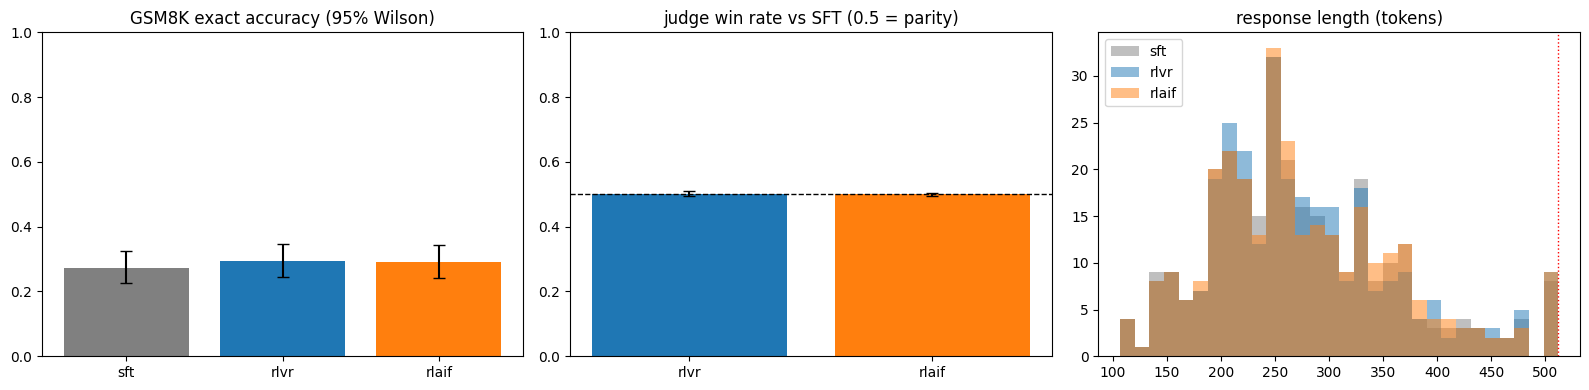

In [17]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from common.data import load_yaml
from task5_feedback.compare_feedback import run_all, POLICIES
cfg = load_yaml('configs/feedback.yaml'); R = 'results/task5_feedback'
out = run_all(cfg)
pd.set_option('display.width', 250, 'display.max_columns', 50)
G = out['gsm']
cols = ['n', 'exact_acc', 'exact_acc_lo', 'exact_acc_hi', 'win_vs_sft', 'win_vs_sft_lo', 'win_vs_sft_hi', 'W', 'T', 'L',
        'has_final_rate', 'strict_format_rate', 'truncated_rate', 'mean_tokens', 'median_tokens', 'mean_words']
print('== GSM8K: policy comparison (has_final = verifier-readable `#### n`; strict = exactly one marker, on the last line) ==')
display(G['policy'][cols].round(3))
print('Head-to-head under the judge (A = RLVR, B = RLAIF):', G['h2h'])
print('\n== Paired exact McNemar tests on accuracy (same prompts) =='); display(G['tests'].round(4))
print('== Verifier vs judge agreement on the same pairs ==')
print('decisive = exactly one of the two responses is correct; verifier_tie = both correct or both wrong (verifier cannot rank)')
display(G['agreement'].round(3))
print('K=3 direct-RLAIF group reward vs binary verifier on the same responses:', json.dumps(G['group_summary'], indent=1))
print('Judge position diagnostic (picked_first_shown ≈ 0.5 means no position bias):', G['position'])

t = G['policy']
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(POLICIES, t.exact_acc, yerr=[t.exact_acc - t.exact_acc_lo, t.exact_acc_hi - t.exact_acc], capsize=4, color=['grey', 'tab:blue', 'tab:orange'])
ax[0].set_title('GSM8K exact accuracy (95% Wilson)'); ax[0].set_ylim(0, 1)
w = t.loc[['rlvr', 'rlaif']]
ax[1].bar(['rlvr', 'rlaif'], w.win_vs_sft, yerr=[(w.win_vs_sft - w.win_vs_sft_lo).clip(lower=0), (w.win_vs_sft_hi - w.win_vs_sft).clip(lower=0)], capsize=4, color=['tab:blue', 'tab:orange'])
ax[1].axhline(0.5, ls='--', c='k', lw=1); ax[1].set_ylim(0, 1); ax[1].set_title('judge win rate vs SFT (0.5 = parity)')
gg = pd.concat([pd.read_json(f'{R}/gen_gsm_{p}.jsonl', lines=True) for p in POLICIES])
for p, c in zip(POLICIES, ['grey', 'tab:blue', 'tab:orange']):
    ax[2].hist(gg[gg.policy == p].response_tokens, bins=30, alpha=.5, label=p, color=c)
ax[2].axvline(cfg['math_max_new_tokens'], c='r', ls=':', lw=1); ax[2].legend(); ax[2].set_title('response length (tokens)')
plt.tight_layout(); plt.savefig(f'{R}/gsm_comparison.png', dpi=130); plt.show()

## 4. Reward-sensitivity and robustness (controlled diagnostic set)
For each controlled pair: fraction where the mechanism prefers the diagnostically better response, ties, and wrong preferences — for the **exact verifier** and the **AI judge**.

* **Reasoning sensitivity** `S_reason = Pr[R(clean) > R(reason-corrupt)]` (final answer held correct). A binary verifier is *expected* to tie here — that invariance is a result, not an accuracy error.
* **Outcome sensitivity** `S_outcome = Pr[R(correct final) > R(wrong final)]` (reasoning held ≈fixed; also reported for the gold-number distractor).
* **Filler** (clean vs. same answer + persuasive filler): the judge should not prefer the filler version; a high `S_reason` is only meaningful if the judge does **not** also reward filler / verbosity.
* Pairs without a diagnostic ground truth (e.g. corrupted reasoning + right answer vs. good reasoning + wrong answer) show *which* signal each mechanism follows: process or outcome.
* Per-variant **RLAIF group reward** = the K=5 win rate the judge would assign during RLAIF training if these five responses were one group.

== Controlled pairs WITH a diagnostically better response (better / tie / wrong preference) ==


,family,n,verifier_better,verifier_tie,verifier_wrong,judge_better,judge_tie,judge_wrong
pair,,,,,,,,
clean>reason_corrupt,reasoning sensitivity,20,0.0,1.0,0.0,0.00,1.00,0.00
clean>wrong_final,outcome sensitivity,20,1.0,0.0,0.0,0.00,1.00,0.00
clean>filler,style / verbosity,20,0.0,1.0,0.0,0.00,0.75,0.25
clean>gold_distractor,outcome sensitivity (distractor),20,1.0,0.0,0.0,0.25,0.70,0.05
filler>reason_corrupt,cross,20,0.0,1.0,0.0,0.15,0.80,0.05
filler>wrong_final,style vs outcome,20,1.0,0.0,0.0,0.15,0.85,0.00
filler>gold_distractor,style vs outcome,20,1.0,0.0,0.0,0.25,0.70,0.05


== Pairs WITHOUT ground truth: which side each mechanism favours ==


,family,n,verifier_prefers_first,verifier_tie,verifier_prefers_second,judge_prefers_first,judge_tie,judge_prefers_second
pair,,,,,,,,
reason_corrupt vs wrong_final,process vs outcome,20,1.0,0.0,0.0,0.05,0.95,0.00
reason_corrupt vs gold_distractor,process vs outcome,20,1.0,0.0,0.0,0.10,0.85,0.05
wrong_final vs gold_distractor,distractor (no gold),20,0.0,1.0,0.0,0.00,1.00,0.00


== Sensitivities ==


S   tie  wrong     n
mechanism quantity                                                                
verifier  S_reason (clean > reason_corrupt)               0.000  1.00  0.000  20.0
          S_outcome (clean > wrong_final)                 1.000  0.00  0.000  20.0
          S_outcome_distractor (clean > gold_distractor)  1.000  0.00  0.000  20.0
          filler (clean > filler)                         0.000  1.00  0.000  20.0
          S_outcome_pooled                                1.000  0.00  0.000  40.0
judge     S_reason (clean > reason_corrupt)               0.000  1.00  0.000  20.0
          S_outcome (clean > wrong_final)                 0.000  1.00  0.000  20.0
          S_outcome_distractor (clean > gold_distractor)  0.250  0.70  0.050  20.0
          filler (clean > filler)                         0.000  0.75  0.250  20.0
          S_outcome_pooled                                0.125  0.85  0.025  40.0

== Per perturbation category: verifier reward, RLAIF K=5 group reward, length ==


,n,verifier_reward,rlaif_group_reward,rlaif_group_reward_sd,mean_words,mean_rlaif_rank,top_or_tied_rate,strict_top_rate
variant,,,,,,,,
clean,20,1.0,0.494,0.086,49.7,2.950,0.50,0.05
reason_corrupt,20,1.0,0.500,0.081,49.7,2.825,0.50,0.10
wrong_final,20,0.0,0.475,0.051,49.7,3.300,0.35,0.00
filler,20,1.0,0.588,0.135,59.7,2.200,0.75,0.35
gold_distractor,20,0.0,0.444,0.143,17.0,3.725,0.40,0.05


Judge position diagnostic on the diagnostic set: {'n_nonidentical': 200, 'tie_rate': 0.86, 'picked_first_shown_rate_non_tie': 0.25, 'identical_pairs': 0}


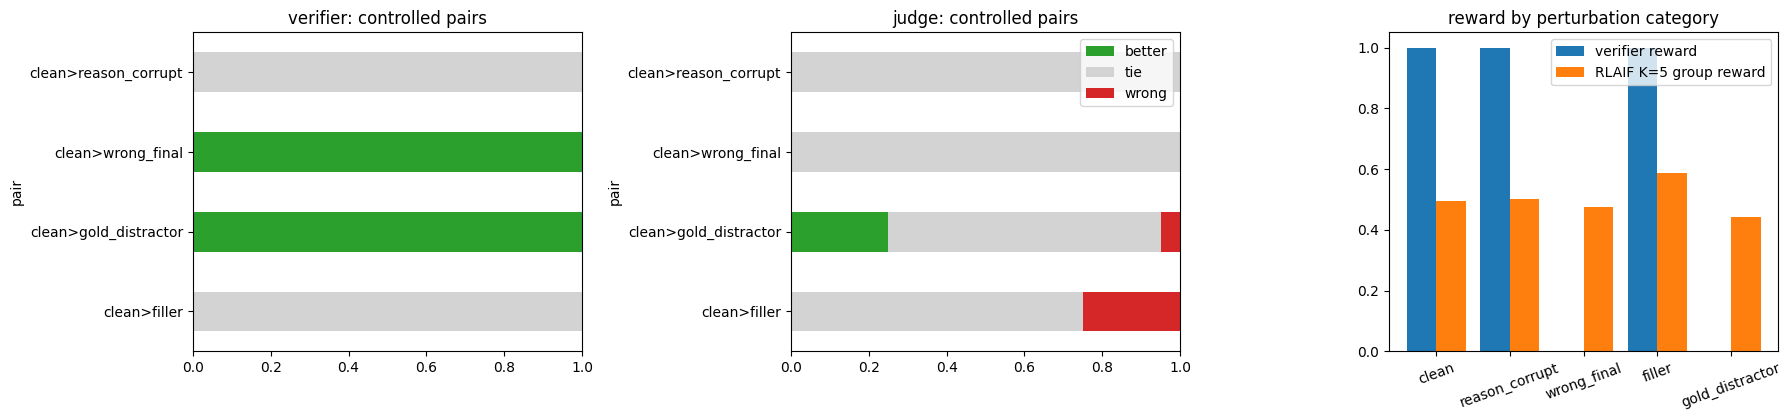

Within-problem correlation of RLAIF group reward with length (words): 0.428 | with verifier reward: 0.501


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/tmp/ipykernel_5017/2123155520.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  round(v.groupby('problem_id').apply(lambda d: d.rlaif_group_reward.corr(d.response_words)).mean(), 3),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_funct

In [18]:
Dg = out['diag']
pt = Dg['pair_table']
gt = pt[pt.has_ground_truth][['family', 'n', 'verifier_better', 'verifier_tie', 'verifier_wrong', 'judge_better', 'judge_tie', 'judge_wrong']]
print('== Controlled pairs WITH a diagnostically better response (better / tie / wrong preference) =='); display(gt.round(3))
ng = pt[~pt.has_ground_truth][['family', 'n', 'verifier_prefers_first', 'verifier_tie', 'verifier_prefers_second', 'judge_prefers_first', 'judge_tie', 'judge_prefers_second']]
print('== Pairs WITHOUT ground truth: which side each mechanism favours =='); display(ng.round(3))
print('== Sensitivities =='); display(Dg['sensitivity'].round(3))
print('== Per perturbation category: verifier reward, RLAIF K=5 group reward, length =='); display(Dg['variant_table'].round(3))
print('Judge position diagnostic on the diagnostic set:', Dg['position'])

main4 = ['clean>reason_corrupt', 'clean>wrong_final', 'clean>gold_distractor', 'clean>filler']
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
for a, mech in zip(ax[:2], ['verifier', 'judge']):
    pt.loc[main4, [f'{mech}_better', f'{mech}_tie', f'{mech}_wrong']].set_axis(['better', 'tie', 'wrong'], axis=1).plot.barh(
        stacked=True, ax=a, color=['tab:green', 'lightgrey', 'tab:red'], legend=(mech == 'judge'))
    a.set_title(f'{mech}: controlled pairs'); a.set_xlim(0, 1); a.invert_yaxis()
vt = Dg['variant_table']
x = np.arange(len(vt)); ax[2].bar(x - .2, vt.verifier_reward, .4, label='verifier reward'); ax[2].bar(x + .2, vt.rlaif_group_reward, .4, label='RLAIF K=5 group reward')
ax[2].set_xticks(x); ax[2].set_xticklabels(vt.index, rotation=20); ax[2].legend(); ax[2].set_title('reward by perturbation category'); ax[2].set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(f'{R}/diagnostic_sensitivity.png', dpi=130); plt.show()

v = Dg['variants']
print('Within-problem correlation of RLAIF group reward with length (words):',
      round(v.groupby('problem_id').apply(lambda d: d.rlaif_group_reward.corr(d.response_words)).mean(), 3),
      '| with verifier reward:', round(v.groupby('problem_id').apply(lambda d: d.rlaif_group_reward.corr(d.verifier_reward)).mean(), 3))

## 5. Out-of-domain comparison (fixed SVAMP-100, no retraining)
Same policies, decoding, verifier and judge protocol. Drop = GSM8K metric − SVAMP metric.

== SVAMP-100: policy comparison ==


,n,exact_acc,exact_acc_lo,exact_acc_hi,win_vs_sft,win_vs_sft_lo,win_vs_sft_hi,W,T,L,has_final_rate,strict_format_rate,truncated_rate,mean_tokens,median_tokens,mean_words
policy,,,,,,,,,,,,,,,,
sft,100,0.42,0.328,0.518,0.500,NaN,NaN,NaN,NaN,NaN,0.55,0.36,0.0,163.35,143.0,107.77
rlvr,100,0.46,0.366,0.557,0.515,0.495,0.540,4.0,95.0,1.0,0.58,0.39,0.0,164.41,143.0,108.14
rlaif,100,0.48,0.385,0.577,0.510,0.500,0.525,2.0,98.0,0.0,0.62,0.40,0.0,164.32,140.0,107.93


Head-to-head (A = RLVR, B = RLAIF): {'rlvr_win_rate_vs_rlaif': 0.51, 'lo': 0.49, 'hi': 0.53, 'rlvr_wins': 3, 'ties': 96, 'rlaif_wins': 1, 'n': 100}

== Drop from in-domain (GSM8K → SVAMP) ==


,acc_gsm,acc_svamp,acc_drop,acc_rel_drop,acc_gain_vs_sft_gsm,acc_gain_vs_sft_svamp,win_vs_sft_gsm,win_vs_sft_svamp,win_drop,strict_format_gsm,strict_format_svamp,mean_tokens_gsm,mean_tokens_svamp
policy,,,,,,,,,,,,,
sft,0.273,0.42,-0.147,-0.537,0.000,0.00,0.500,0.500,NaN,0.210,0.36,275.097,163.35
rlvr,0.293,0.46,-0.167,-0.568,0.020,0.04,0.502,0.515,-0.013,0.203,0.39,275.750,164.41
rlaif,0.290,0.48,-0.190,-0.655,0.017,0.06,0.500,0.510,-0.010,0.203,0.40,276.640,164.32


== Paired McNemar on SVAMP accuracy ==


...

,n,agreement_3way,cohen_kappa,n_decisive,judge_picks_correct,judge_tie_when_decisive,judge_picks_incorrect,n_verifier_tie,judge_decisive_when_verifier_tie,n_both_correct,judge_decisive_both_correct,n_both_wrong,judge_decisive_both_wrong
comparison,,,,,,,,,,,,,
rlvr vs sft,100,0.950,0.523,6,0.500,0.500,0.0,94,0.021,41,0.024,53,0.019
rlaif vs sft,100,0.960,0.485,6,0.333,0.667,0.0,94,0.000,42,0.000,52,0.000
rlvr vs rlaif,100,0.960,0.322,2,0.500,0.500,0.0,98,0.031,46,0.043,52,0.019
pooled,300,0.957,0.461,14,0.429,0.571,0.0,286,0.017,129,0.023,157,0.013


== Failure types (share of responses) ==


failure_type  correct  wrong_final  gold_in_reasoning_wrong_final  missing_final  truncated_no_final
      policy                                                                                        
GSM8K sft       0.273        0.070                          0.010          0.627               0.020
      rlvr      0.293        0.063                          0.007          0.613               0.023
      rlaif     0.290        0.060                          0.013          0.613               0.023
SVAMP sft       0.420        0.070                          0.060          0.450               0.000
      rlvr      0.460        0.060                          0.060          0.420               0.000
      rlaif     0.480        0.070                          0.070          0.380               0.000

== SVAMP accuracy by problem type ==


mean                size         
policy           rlaif   rlvr    sft rlaif rlvr sft
svamp_type                                         
Addition         0.250  0.250  0.250    20   20  20
Common-Division  0.500  0.429  0.500    14   14  14
Multiplication   0.111  0.111  0.111     9    9   9
Subtraction      0.614  0.596  0.509    57   57  57

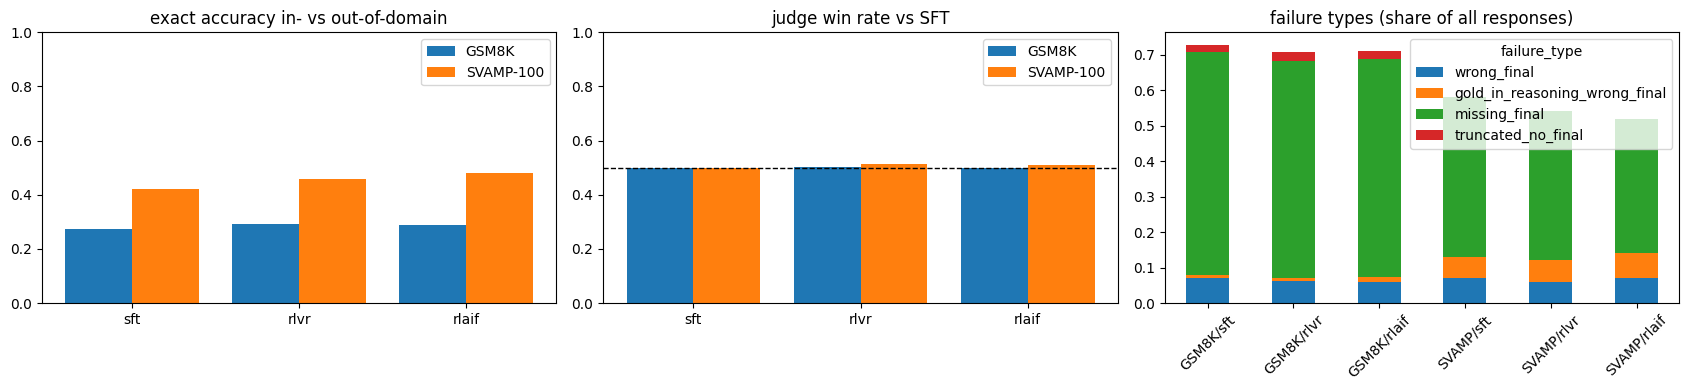

In [19]:
T = out['transfer']
print('== SVAMP-100: policy comparison =='); display(T['policy'][cols].round(3))
print('Head-to-head (A = RLVR, B = RLAIF):', T['h2h'])
print('\n== Drop from in-domain (GSM8K → SVAMP) =='); display(out['drop'].round(3))
print('== Paired McNemar on SVAMP accuracy =='); display(T['tests'].round(4))
print('== Verifier vs judge agreement on SVAMP =='); display(T['agreement'].round(3))
print('== Failure types (share of responses) ==')
display(pd.concat({'GSM8K': G['failures'], 'SVAMP': T['failures']}).round(3))
st = pd.read_json(f'{R}/gen_transfer_sft.jsonl', lines=True)
if 'svamp_type' in st:
    sv = pd.concat([pd.read_json(f'{R}/gen_transfer_{p}.jsonl', lines=True) for p in POLICIES])
    print('== SVAMP accuracy by problem type =='); display(sv.pivot_table(index='svamp_type', columns='policy', values='exact', aggfunc=['mean', 'size']).round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
dr = out['drop']; x = np.arange(3)
ax[0].bar(x - .2, dr.acc_gsm, .4, label='GSM8K'); ax[0].bar(x + .2, dr.acc_svamp, .4, label='SVAMP-100')
ax[0].set_xticks(x); ax[0].set_xticklabels(POLICIES); ax[0].legend(); ax[0].set_ylim(0, 1); ax[0].set_title('exact accuracy in- vs out-of-domain')
ax[1].bar(x - .2, dr.win_vs_sft_gsm, .4, label='GSM8K'); ax[1].bar(x + .2, dr.win_vs_sft_svamp, .4, label='SVAMP-100')
ax[1].axhline(.5, ls='--', c='k', lw=1); ax[1].set_xticks(x); ax[1].set_xticklabels(POLICIES); ax[1].set_ylim(0, 1); ax[1].legend(); ax[1].set_title('judge win rate vs SFT')
ft = pd.concat({'GSM8K': G['failures'], 'SVAMP': T['failures']}).drop(columns='correct')
ft.index = [f'{d}/{p}' for d, p in ft.index]; ft.plot.bar(stacked=True, ax=ax[2]); ax[2].set_title('failure types (share of all responses)'); ax[2].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(f'{R}/transfer_comparison.png', dpi=130); plt.show()

## 6. Qualitative diagnostic evidence
Examples chosen automatically to span reasoning-only corruption, persuasive filler, and wrong-final / gold-distractor behaviour, preferring cases where the verifier and the judge **disagree**. Read them before writing the attribution.

In [20]:
import textwrap
P, V = Dg['pairs'], Dg['variants'].set_index(['problem_id', 'variant'])
def show_pair(row, n=700):
    pid = row.problem_id
    prob, gold = V.loc[(pid, row['first'])].problem, V.loc[(pid, row['first'])].gold_final
    print('=' * 110)
    print(f"problem {pid} | pair {row.pair} | gold {gold} | verifier: {row.verifier_first:.0f} vs {row.verifier_second:.0f} -> {row.verifier_pref} ({row.verifier_outcome})"
          f" | judge -> {row.judge_pref} ({row.judge_outcome})")
    print('PROBLEM:', textwrap.shorten(prob, 350))
    for side in ('first', 'second'):
        r = V.loc[(pid, row[side])]
        print(f"\n  [{side}: {row[side]} | final={r.pred_final} | {r.response_words} words]\n  " + r.response[:n].replace('\n', '\n  '))
def pick(pair, prefer=('wrong', 'tie', 'better'), k=1):
    d = P[P.pair == pair]
    for o in prefer:
        s = d[d.judge_outcome == o]
        if len(s): return s.head(k)
    return d.head(k)
print('########## REASONING-ONLY CORRUPTION (final held correct) — one the judge catches, one it misses (if both exist) ##########')
d = P[P.pair == 'clean>reason_corrupt']
for sub in (d[d.judge_outcome == 'better'], d[d.judge_outcome != 'better']):
    for _, r in sub.head(1).iterrows(): show_pair(r)
print('\n########## PERSUASIVE FILLER (same correct answer + irrelevant persuasive text) ##########')
for _, r in pick('clean>filler', ('wrong', 'tie', 'better')).iterrows(): show_pair(r)
print('\n########## WRONG FINAL / GOLD DISTRACTOR ##########')
for _, r in pick('clean>gold_distractor', ('wrong', 'tie', 'better')).iterrows(): show_pair(r)
for _, r in pick('clean>wrong_final', ('wrong', 'tie', 'better')).iterrows(): show_pair(r)
print('\n########## PROCESS vs OUTCOME (corrupt reasoning + right answer  vs  good reasoning + wrong answer) ##########')
for _, r in P[P.pair == 'reason_corrupt vs wrong_final'].head(1).iterrows(): show_pair(r)

########## REASONING-ONLY CORRUPTION (final held correct) — one the judge catches, one it misses (if both exist) ##########
problem 23 | pair clean>reason_corrupt | gold 8 | verifier: 1 vs 1 -> TIE (tie) | judge -> TIE (tie)
PROBLEM: A candle melts by 2 centimeters every hour that it burns. How many centimeters shorter will a candle be after burning from 1:00 PM to 5:00 PM?

  [first: clean | final=8 | 24 words]
  The candle burns for 5 - 1 = <<5-1=4>>4 hours.
  Thus, the candle will be 2 * 4 = <<2*4=8>>8 centimeters shorter.
  #### 8

  [second: reason_corrupt | final=8 | 24 words]
  The candle burns for 5 - 1 = <<5-1=5>>4 hours.
  Thus, the candle will be 2 * 4 = <<2*4=8>>8 centimeters shorter.
  #### 8

########## PERSUASIVE FILLER (same correct answer + irrelevant persuasive text) ##########
problem 113 | pair clean>filler | gold 25 | verifier: 1 vs 1 -> TIE (tie) | judge -> B (wrong)
PROBLEM: Ryan plants 2 flowers a day in his garden. After 15 days, how many flowers does he have i

In [21]:
# In-domain verifier–judge disagreements on real policy outputs
J = pd.read_json(f'{R}/judge_gsm.jsonl', lines=True, dtype={'source_index': str})
gens = {p: pd.read_json(f'{R}/gen_gsm_{p}.jsonl', lines=True, dtype={'source_index': str}).set_index('source_index') for p in POLICIES}
def show_real(r, n=600):
    a, b = gens[r.a_policy].loc[r.source_index], gens[r.b_policy].loc[r.source_index]
    print('=' * 110); print(f"{r.source_index} | {r.a_policy} vs {r.b_policy} | gold {a.gold_final} | verifier {r.verifier_pref} | judge {r.judge_pref}")
    print('PROBLEM:', textwrap.shorten(a.question, 300))
    for name, x in ((r.a_policy, a), (r.b_policy, b)):
        print(f"\n  [{name} | final={x.get('pred_final')} | exact={x.exact:.0f} | {x.response_tokens} tok]\n  " + x.response[:n].replace('\n', '\n  '))
cases = [('judge prefers the INCORRECT response', J[(J.verifier_pref != 'TIE') & (J.judge_pref != 'TIE') & (J.judge_pref != J.verifier_pref)]),
         ('both wrong (verifier ties) but judge ranks them', J[(J.verifier_pref == 'TIE') & (J.a_exact == 0) & (J.judge_pref != 'TIE')]),
         ('both correct (verifier ties) but judge ranks them', J[(J.verifier_pref == 'TIE') & (J.a_exact == 1) & (J.judge_pref != 'TIE')])]
for title, d in cases:
    print(f'\n########## {title}: {len(d)} cases ##########')
    for _, r in d.head(1).iterrows(): show_real(r)


########## judge prefers the INCORRECT response: 2 cases ##########
466 | rlvr vs sft | gold 1 | verifier A | judge B
PROBLEM: Becky bought 20 apples for 45 cents each and received a $1 discount. Kelly bought 20 apples for 50 cents each and received a 10 percent discount. How much more did Kelly pay than Becky?

  [rlvr | final=1.0 | exact=1 | 311 tok]
  Step 1: Calculate the total cost for Becky.
  Becky bought 20 apples at 45 cents each.
  Total cost = Number of apples × Price per apple
  Total cost = 20 × 0.45
  Total cost = $9
  
  Step 2: Apply the discount to Becky's total cost.
  Becky received a $1 discount on her purchase.
  Discounted total = Total cost - Discount
  Discounted total = $9 - $1
  Discounted total = $8
  
  Step 3: Calculate the total cost for Kelly.
  Kelly bought 20 apples at 50 cents each.
  Total cost = Number of apples × Price per apple
  Total cost = 20 × 0.50
  Total cost = $10
  
  Step 4: Apply the discount to Kelly's total cost.
  Kelly received a

  

## 7. Cost and judge reliability

In [22]:
C = out['cost']
print(json.dumps(C, indent=1, default=float))
print(f"\nOne exact-verifier check ≈ {C['verifier_us_per_check']:.1f} µs; one pairwise judge call ≈ {C['judge_s_per_pairwise_call']:.2f} s "
      f"(≈{C['judge_over_verifier_ratio']:.0f}× slower). A direct-RLAIF group of K responses needs K(K−1)/2 judge calls "
      f"(K=8 → 28 calls ≈ {C['est_judge_s_per_group(K=8)']:.0f} s) vs K verifier checks.")
print('Judge tie / position diagnostics — GSM8K:', G['position'], '| SVAMP:', T['position'], '| diagnostics:', Dg['position'])

{
 "verifier_us_per_check": 0.9976586999982828,
 "judge_s_per_pairwise_call": 0.48698046720060345,
 "judge_calls_timed": 339,
 "judge_over_verifier_ratio": 488123.31030786544,
 "judge_calls_per_rlaif_group(K)": {
  "4": 6,
  "8": 28,
  "16": 120
 },
 "est_judge_s_per_group(K=8)": 13.635453081616896,
 "verifier_checks_per_group(K=8)": 8,
 "generation_timing_s": {
  "gsm/sft": {
   "seconds": 362.09856152534485,
   "n": 300
  },
  "gsm/rlvr": {
   "seconds": 436.4941110610962,
   "n": 300
  },
  "gsm/rlaif": {
   "seconds": 429.2152554988861,
   "n": 300
  },
  "transfer/sft": {
   "seconds": 82.32888650894165,
   "n": 100
  },
  "transfer/rlvr": {
   "seconds": 103.92735052108765,
   "n": 100
  },
  "transfer/rlaif": {
   "seconds": 104.22451996803284,
   "n": 100
  }
 }
}

One exact-verifier check ≈ 1.0 µs; one pairwise judge call ≈ 0.49 s (≈488123× slower). A direct-RLAIF group of K responses needs K(K−1)/2 judge calls (K=8 → 28 calls ≈ 14 s) vs K verifier checks.
Judge tie / position

## 8. Evidence sheet for the research questions
Prints the specific numbers each RQ should cite. Write the final answers in the markdown cell below **after** reading §3–§7 and the qualitative examples.

In [23]:
s = Dg['sensitivity']; pt = Dg['pair_table']; ag = G['agreement'].loc['pooled']
f = lambda x: f'{x:.2f}'
print('RQ1 — where the judge distinguishes what the verifier ties')
print('  verifier ties (both right or both wrong):', int(ag.n_verifier_tie), 'pairs; judge decisive on', f(ag.judge_decisive_when_verifier_tie),
      '| both correct:', f(ag.judge_decisive_both_correct), '| both wrong:', f(ag.judge_decisive_both_wrong))
print('  S_reason  verifier:', f(s.loc[('verifier', 'S_reason (clean > reason_corrupt)'), 'S']), 'tie', f(s.loc[('verifier', 'S_reason (clean > reason_corrupt)'), 'tie']),
      '| judge:', f(s.loc[('judge', 'S_reason (clean > reason_corrupt)'), 'S']), 'tie', f(s.loc[('judge', 'S_reason (clean > reason_corrupt)'), 'tie']),
      'wrong', f(s.loc[('judge', 'S_reason (clean > reason_corrupt)'), 'wrong']))
print('\nRQ2 — style / verbosity / persuasion')
print('  clean>filler  judge better/tie/wrong:', *[f(pt.loc['clean>filler', f'judge_{o}']) for o in ('better', 'tie', 'wrong')])
print('  filler>wrong_final judge better:', f(pt.loc['filler>wrong_final', 'judge_better']), '| filler>gold_distractor judge better:', f(pt.loc['filler>gold_distractor', 'judge_better']))
print('  RLAIF group reward  clean:', f(Dg['variant_table'].loc['clean', 'rlaif_group_reward']), ' filler:', f(Dg['variant_table'].loc['filler', 'rlaif_group_reward']),
      '| corr(group reward, words) GSM8K:', f(G['group_summary']['corr_group_reward_vs_words']))
print('  length: mean tokens', G['policy'].mean_tokens.round(1).to_dict())
print('\nRQ3 — vulnerability per category')
print(gt[['verifier_better', 'verifier_tie', 'verifier_wrong', 'judge_better', 'judge_tie', 'judge_wrong']].round(2).to_string())
print('  process vs outcome (reason_corrupt vs wrong_final): verifier prefers corrupt-reasoning/right-answer',
      f(pt.loc['reason_corrupt vs wrong_final', 'verifier_prefers_first']), '| judge', f(pt.loc['reason_corrupt vs wrong_final', 'judge_prefers_first']))
print('  wrong_final vs gold_distractor: judge prefers distractor', f(pt.loc['wrong_final vs gold_distractor', 'judge_prefers_second']),
      '| verifier reward on gold_distractor:', f(Dg['variant_table'].loc['gold_distractor', 'verifier_reward']))
print('\nRQ4 — transfer'); print(out['drop'][['acc_gsm', 'acc_svamp', 'acc_drop', 'acc_gain_vs_sft_gsm', 'acc_gain_vs_sft_svamp', 'win_vs_sft_gsm', 'win_vs_sft_svamp']].round(3).to_string())
print('  SVAMP McNemar:', T['tests'][['A', 'B', 'only_A_correct', 'only_B_correct', 'mcnemar_p']].round(4).to_dict('records'))
print('  failure types SVAMP:\n', T['failures'].round(2).to_string())

RQ1 — where the judge distinguishes what the verifier ties
  verifier ties (both right or both wrong): 872 pairs; judge decisive on 0.01 | both correct: 0.00 | both wrong: 0.01
  S_reason  verifier: 0.00 tie 1.00 | judge: 0.00 tie 1.00 wrong 0.00

RQ2 — style / verbosity / persuasion
  clean>filler  judge better/tie/wrong: 0.00 0.75 0.25
  filler>wrong_final judge better: 0.15 | filler>gold_distractor judge better: 0.25
  RLAIF group reward  clean: 0.49  filler: 0.59 | corr(group reward, words) GSM8K: 0.02
  length: mean tokens {'sft': 275.1, 'rlvr': 275.8, 'rlaif': 276.6}

RQ3 — vulnerability per category
                        verifier_better  verifier_tie  verifier_wrong  judge_better  judge_tie  judge_wrong
pair                                                                                                       
clean>reason_corrupt                0.0           1.0             0.0          0.00       1.00         0.00
clean>wrong_final                   1.0           0.0         

## Discussion (fill in from the numbers above — keep each answer to a short paragraph)

**Feedback-source comparison**
- *Coverage:* the verifier gives signal only through the designated `#### n` (binary, ties all-correct and all-wrong groups → zero within-group advantage for those prompts). The judge ranks every pair (see `judge_decisive_when_verifier_tie`, K=3 group reward spread). → …
- *Noise:* verifier is exact w.r.t. its spec (check `verifier_*` rows of the diagnostic table, including gold-distractor). Judge: tie rate, position bias (`picked_first_shown_rate`), `judge_picks_incorrect` on decisive pairs, wrong preferences on controlled pairs. → …
- *Exploitability:* verifier — format/answer-only hacks (correct `####` with corrupt reasoning gets full reward; anything outside the designated field is ignored). Judge — filler/persuasion and length (clean>filler, corr with words). → …
- *Inference cost:* µs per verifier check vs seconds per judge call; K(K−1)/2 calls per group (§7). → …

**RQ1.** Where does AI preference feedback distinguish responses the binary verifier treats identically, and when is that useful? → …

**RQ2.** When does the judge make an incorrect distinction because of style, verbosity or persuasion, and how does that change the reading of its S_reason? → …

**RQ3.** Which reward source is more vulnerable to each diagnostic category; what does the pattern say about verifier specification vs judge bias? → …

**RQ4.** Which behaviours transfer to SVAMP, and what supports or weakens the claim that either feedback source promotes more general reasoning? (Use the accuracy drop *and* gain over SFT on each set, McNemar p-values, format compliance and failure types; 100 OOD items → wide CIs.) → …

## Backup + download

In [24]:
import shutil, time, os
dst = f"/content/drive/MyDrive/ATML_PA2_task5/backup_{time.strftime('%Y%m%d_%H%M%S')}"
os.makedirs(dst, exist_ok=True)
shutil.copytree(os.path.realpath('results/task5_feedback'), f'{dst}/results/task5_feedback', dirs_exist_ok=True)
for d in ('task5_feedback', 'tests'):
    shutil.copytree(d, f'{dst}/code/{d}', dirs_exist_ok=True, ignore=shutil.ignore_patterns('__pycache__'))
print('Backed up to', dst)

Backed up to /content/drive/MyDrive/ATML_PA2_task5/backup_20261017_233537


In [27]:
!zip -qr /content/task5_results.zip /content/ATML-PA2-LLM-PostTraining/results/task5_feedback -x '*/judge_cache.json'
from google.colab import files
files.download('/content/task5_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>